# F4 career analytics: exploration

Run `make all` first so `data/processed/` exists. This notebook explores the data behind
`reports/results.md`: coverage, how drivers move between series, and individual careers.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import pandas as pd, matplotlib.pyplot as plt
from f4ca.config import Config
cfg = Config()
f4 = pd.read_csv(cfg.processed_dir / "f4_results.csv")
ladder = pd.read_csv(cfg.processed_dir / "ladder.csv")
drivers = pd.read_csv(cfg.processed_dir / "drivers.csv")
coverage = pd.read_csv(cfg.processed_dir / "coverage.csv")
f4.shape, ladder.shape, drivers.shape

((2898, 18), (1625, 16), (1650, 34))

## 1. Data coverage
Which season pages were found and parsed? Gaps here limit everything downstream.

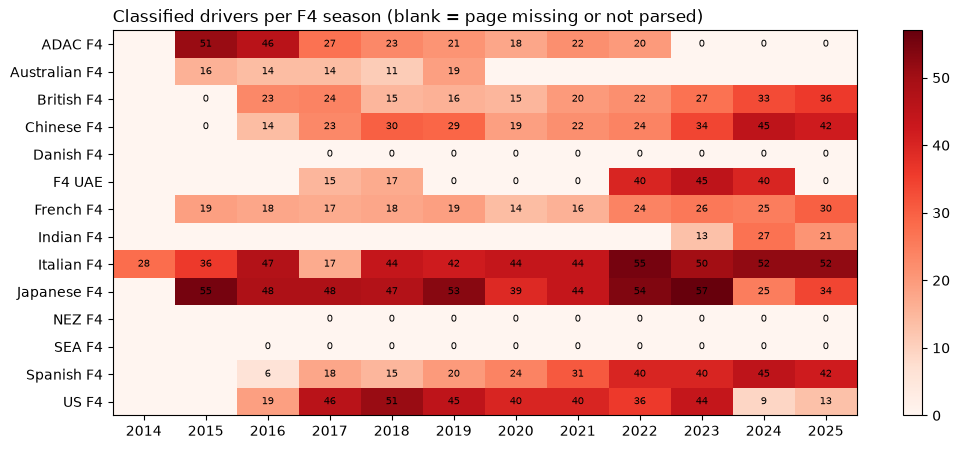

,kind,tier,series,season,title,status,drivers
20,f4,f4,ADAC F4,2023,2023 ADAC Formula 4 Championship,missing,0
21,f4,f4,ADAC F4,2024,2024 ADAC Formula 4 Championship,missing,0
22,f4,f4,ADAC F4,2025,2025 ADAC Formula 4 Championship,missing,0
23,f4,f4,British F4,2015,2015 F4 British Championship,missing,0
81,f4,f4,Chinese F4,2015,2015 F4 Chinese Championship,missing,0
92,f4,f4,SEA F4,2016,2016 F4 South East Asia Championship,missing,0
93,f4,f4,SEA F4,2017,2017 F4 South East Asia Championship,missing,0
94,f4,f4,SEA F4,2018,2018 F4 South East Asia Championship,missing,0
95,f4,f4,SEA F4,2019,2019 F4 South East Asia Championship,missing,0
96,f4,f4,SEA F4,2020,2020 F4 South East Asia Championship,missing,0


In [3]:
grid = (coverage[coverage.kind == "f4"]
        .pivot_table(index="series", columns="season", values="drivers", aggfunc="sum"))
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(grid.fillna(0), cmap="Reds", aspect="auto")
ax.set_xticks(range(len(grid.columns)), grid.columns); ax.set_yticks(range(len(grid.index)), grid.index)
for (i, j), v in pd.DataFrame(grid.values).stack().dropna().items():
    ax.text(j, i, int(v), ha="center", va="center", fontsize=7)
ax.set_title("Classified drivers per F4 season (blank = page missing or not parsed)", loc="left")
plt.colorbar(im); plt.show()
coverage[coverage.status != "parsed"]

## 2. Data quality checks

In [4]:
checks = {
    "duplicate driver-season-series rows": f4.duplicated(["driver_id", "series", "season"]).sum(),
    "rows with no race entries": (f4.entries == 0).sum(),
    "drivers matched by name only (no article)": f4.driver_id.str.startswith("name:").mean(),
    "finishes > entries": (f4.finishes > f4.entries).sum(),
}
pd.Series(checks)

duplicate driver-season-series rows          0.000000
rows with no race entries                    0.000000
drivers matched by name only (no article)    0.515528
finishes > entries                           0.000000
dtype: float64

## 3. How many seasons do drivers spend in F4?

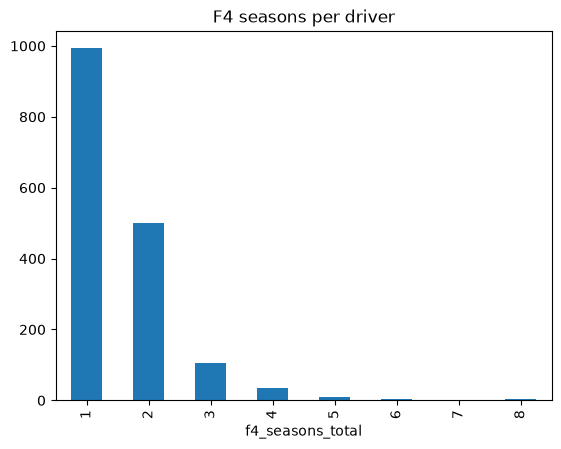

In [5]:
drivers.f4_seasons_total.value_counts().sort_index().plot.bar(title="F4 seasons per driver")
plt.show()

## 4. Where do drivers go next?
The most common first higher category for each F4 debut series.

In [6]:
first_step = (ladder.sort_values("season").merge(drivers[["driver_id", "debut_season", "debut_series"]], on="driver_id")
              .query("season > debut_season").groupby("driver_id").first())
pd.crosstab(first_step.debut_series, first_step.series, margins=True)

series,Euroformula Open,European F3,FIA F2,FIA F3,FRECA,GP3,All
debut_series,,,,,,,
ADAC F4,9,12,0,5,10,2,38
Australian F4,1,0,0,0,1,0,2
British F4,13,0,0,12,6,0,31
Chinese F4,1,1,0,0,0,0,2
F4 UAE,3,0,0,5,4,0,12
French F4,10,1,1,4,19,2,37
Indian F4,0,0,0,0,1,0,1
Italian F4,16,11,0,15,55,1,98
Japanese F4,3,1,1,1,1,0,7


## 5. Look up a career

In [7]:
name = "Antonelli"   # try any surname
mask_f4 = f4.driver.str.contains(name, case=False)
mask_l = ladder.driver.str.contains(name, case=False)
pd.concat([f4[mask_f4].assign(tier="F4"), ladder[mask_l]])[["season", "tier", "series", "driver", "pos", "points", "wins"]].sort_values("season")

,season,tier,series,driver,pos,points,wins
267,2021,F4,Italian F4,Andrea Kimi Antonelli,10,54.0,0
302,2022,F4,Italian F4,Andrea Kimi Antonelli,1,362.0,13
719,2022,F4,ADAC F4,Andrea Kimi Antonelli,1,313.0,9
2780,2022,F4,F4 UAE,Andrea Kimi Antonelli,8,117.0,2
116,2023,regional,FRECA,Andrea Kimi Antonelli,1,300.0,5
1235,2024,f2,FIA F2,Andrea Kimi Antonelli,6,113.0,2
1610,2025,f1,Formula One,Kimi Antonelli,7,150.0,0


## 6. Rookie finish vs outcome, by debut year
Is it getting harder to progress? A falling line at the same finish position would say yes.

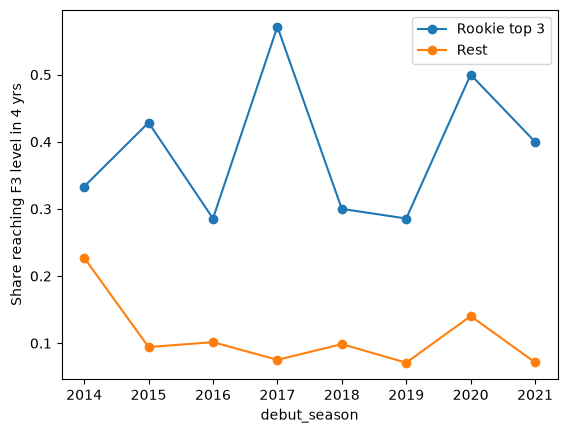

In [8]:
lab = drivers[drivers.labelled]
top3 = lab[lab.best_pos <= 3].groupby("debut_season")["reached_tier3_in_horizon"].mean()
rest = lab[lab.best_pos > 3].groupby("debut_season")["reached_tier3_in_horizon"].mean()
ax = top3.plot(marker="o", label="Rookie top 3"); rest.plot(marker="o", ax=ax, label="Rest")
ax.set_ylabel("Share reaching F3 level in 4 yrs"); ax.legend(); plt.show()